# Spotify Track Analysis

### Data and popularity scores are based off of global listening during October of 2022.

See documentation here: https://www.kaggle.com/datasets/maharshipandya/-spotify-tracks-dataset/data

In [3]:
# ================================================================
# Spotify Tracks — END-TO-END DATA Project
# SQL → Pandas/NumPy → Visualizations → K-Means + Random Forest
# ================================================================

import pandas as pd
import numpy as np
import sqlite3
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import mean_absolute_error, r2_score, silhouette_score, mean_squared_error
import shap
import warnings
import os
import kagglehub

import math
from scipy import stats

warnings.filterwarnings('ignore')

In [4]:

path = kagglehub.dataset_download("maharshipandya/-spotify-tracks-dataset")
print(os.listdir(path))  # confirm the filename

df = pd.read_csv(os.path.join(path, "dataset.csv"))  # adjust to the filename printed above

['dataset.csv']


In [5]:
csv_path = r'C:\Users\conno_leva1li\.cache\kagglehub\datasets\maharshipandya\-spotify-tracks-dataset\versions\1\dataset.csv'

df = pd.read_csv(csv_path)

### Initial Data Exploration

In [6]:
pd.set_option('display.float_format', '{:.4f}'.format)
print(df.describe())

       Unnamed: 0  popularity  duration_ms  danceability      energy  \
count 114000.0000 114000.0000  114000.0000   114000.0000 114000.0000   
mean   56999.5000     33.2385  228029.1531        0.5668      0.6414   
std    32909.1097     22.3051  107297.7126        0.1735      0.2515   
min        0.0000      0.0000       0.0000        0.0000      0.0000   
25%    28499.7500     17.0000  174066.0000        0.4560      0.4720   
50%    56999.5000     35.0000  212906.0000        0.5800      0.6850   
75%    85499.2500     50.0000  261506.0000        0.6950      0.8540   
max   113999.0000    100.0000 5237295.0000        0.9850      1.0000   

              key    loudness        mode  speechiness  acousticness  \
count 114000.0000 114000.0000 114000.0000  114000.0000   114000.0000   
mean       5.3091     -8.2590      0.6376       0.0847        0.3149   
std        3.5600      5.0293      0.4807       0.1057        0.3325   
min        0.0000    -49.5310      0.0000       0.0000        0

In [7]:
df.head()

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.6760,0.4610,...,-6.7460,0,0.1430,0.0322,0.0000,0.3580,0.7150,87.9170,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.4200,0.1660,...,-17.2350,1,0.0763,0.9240,0.0000,0.1010,0.2670,77.4890,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.4380,0.3590,...,-9.7340,1,0.0557,0.2100,0.0000,0.1170,0.1200,76.3320,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.2660,0.0596,...,-18.5150,1,0.0363,0.9050,0.0001,0.1320,0.1430,181.7400,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.6180,0.4430,...,-9.6810,1,0.0526,0.4690,0.0000,0.0829,0.1670,119.9490,4,acoustic


In [8]:
df.drop(columns=['Unnamed: 0'], inplace=True)

In [9]:
df.isna().sum()

track_id            0
artists             1
album_name          1
track_name          1
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
dtype: int64

In [10]:
df[df['artists'].isna()]

,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
65900,1kR4gIb7nGxHPI3D2ifs59,NaN,NaN,NaN,0,0,False,0.5010,0.5830,7,-9.4600,0,0.0605,0.6900,0.0040,0.0747,0.7340,138.3910,4,k-pop


In [11]:
df.dropna(inplace=True)

In [12]:
df.duplicated().sum()

np.int64(450)

In [13]:
df = df.drop_duplicates()

In [14]:
df.sort_values('popularity', ascending=False).head()

,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
20001,3nqQXoyQOWXiESFLlDF1hG,Sam Smith;Kim Petras,Unholy (feat. Kim Petras),Unholy (feat. Kim Petras),100,156943,False,0.7140,0.4720,2,-7.3750,1,0.0864,0.0130,0.0000,0.2660,0.2380,131.1210,4,dance
81051,3nqQXoyQOWXiESFLlDF1hG,Sam Smith;Kim Petras,Unholy (feat. Kim Petras),Unholy (feat. Kim Petras),100,156943,False,0.7140,0.4720,2,-7.3750,1,0.0864,0.0130,0.0000,0.2660,0.2380,131.1210,4,pop
51664,2tTmW7RDtMQtBk7m2rYeSw,Bizarrap;Quevedo,"Quevedo: Bzrp Music Sessions, Vol. 52","Quevedo: Bzrp Music Sessions, Vol. 52",99,198937,False,0.6210,0.7820,2,-5.5480,1,0.0440,0.0125,0.0330,0.2300,0.5500,128.0330,4,hip-hop
81210,4uUG5RXrOk84mYEfFvj3cK,David Guetta;Bebe Rexha,I'm Good (Blue),I'm Good (Blue),98,175238,True,0.5610,0.9650,7,-3.6730,0,0.0343,0.0038,0.0000,0.3710,0.3040,128.0400,4,pop
30003,4uUG5RXrOk84mYEfFvj3cK,David Guetta;Bebe Rexha,I'm Good (Blue),I'm Good (Blue),98,175238,True,0.5610,0.9650,7,-3.6730,0,0.0343,0.0038,0.0000,0.3710,0.3040,128.0400,4,edm


### Songs appear more than once with different generes 

In [15]:
df = df.drop_duplicates(
    subset=df.columns.difference(['track_genre'])
)

In [16]:
df.sort_values('popularity', ascending=False).head()

,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
20001,3nqQXoyQOWXiESFLlDF1hG,Sam Smith;Kim Petras,Unholy (feat. Kim Petras),Unholy (feat. Kim Petras),100,156943,False,0.7140,0.4720,2,-7.3750,1,0.0864,0.0130,0.0000,0.2660,0.2380,131.1210,4,dance
51664,2tTmW7RDtMQtBk7m2rYeSw,Bizarrap;Quevedo,"Quevedo: Bzrp Music Sessions, Vol. 52","Quevedo: Bzrp Music Sessions, Vol. 52",99,198937,False,0.6210,0.7820,2,-5.5480,1,0.0440,0.0125,0.0330,0.2300,0.5500,128.0330,4,hip-hop
20008,4uUG5RXrOk84mYEfFvj3cK,David Guetta;Bebe Rexha,I'm Good (Blue),I'm Good (Blue),98,175238,True,0.5610,0.9650,7,-3.6730,0,0.0343,0.0038,0.0000,0.3710,0.3040,128.0400,4,dance
67356,5ww2BF9slyYgNOk37BlC4u,Manuel Turizo,La Bachata,La Bachata,98,162637,False,0.8350,0.6790,7,-5.3290,0,0.0364,0.5830,0.0000,0.2180,0.8500,124.9800,4,latin
67359,1IHWl5LamUGEuP4ozKQSXZ,Bad Bunny,Un Verano Sin Ti,Tití Me Preguntó,97,243716,False,0.6500,0.7150,5,-5.1980,0,0.2530,0.0993,0.0003,0.1260,0.1870,106.6720,4,latin


### SECTION 1 — SQL

In [17]:
conn = sqlite3.connect(':memory:')

df.to_sql('spotify', conn, index=False, if_exists='replace')

print(f"Loaded {len(df):,} rows")
print(df.columns.tolist())

Loaded 90,460 rows
['track_id', 'artists', 'album_name', 'track_name', 'popularity', 'duration_ms', 'explicit', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature', 'track_genre']


In [18]:
pd.read_sql('SELECT * FROM spotify LIMIT 5', conn)

,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,0,0.6760,0.4610,1,-6.7460,0,0.1430,0.0322,0.0000,0.3580,0.7150,87.9170,4,acoustic
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,0,0.4200,0.1660,1,-17.2350,1,0.0763,0.9240,0.0000,0.1010,0.2670,77.4890,4,acoustic
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,0,0.4380,0.3590,0,-9.7340,1,0.0557,0.2100,0.0000,0.1170,0.1200,76.3320,4,acoustic
3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,0,0.2660,0.0596,0,-18.5150,1,0.0363,0.9050,0.0001,0.1320,0.1430,181.7400,3,acoustic
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,0,0.6180,0.4430,2,-9.6810,1,0.0526,0.4690,0.0000,0.0829,0.1670,119.9490,4,acoustic


In [19]:
pd.read_sql('SELECT artists, AVG(popularity) AS avg_popularity FROM spotify GROUP BY artists ORDER BY avg_popularity DESC LIMIT 10', conn)

,artists,avg_popularity
0,Sam Smith;Kim Petras,100.0000
1,Bizarrap;Quevedo,99.0000
2,Manuel Turizo,98.0000
3,Bad Bunny;Chencho Corleone,97.0000
4,Bad Bunny;Bomba Estéreo,94.5000
5,Joji,94.0000
6,Beyoncé,93.0000
7,Rema;Selena Gomez,92.0000
8,Harry Styles,92.0000
9,Rauw Alejandro;Lyanno;Brray,91.0000


In [20]:
pd.read_sql(
    'SELECT track_genre, count(*) as genre_count, avg(popularity) as avg_popularity FROM spotify GROUP BY track_genre ORDER BY avg_popularity DESC LIMIT 10'
, conn)

,track_genre,genre_count,avg_popularity
0,k-pop,916,59.4236
1,pop-film,815,59.0969
2,metal,232,56.4224
3,chill,972,53.7387
4,latino,398,51.7889
5,sad,611,50.8953
6,grunge,862,50.5870
7,reggaeton,89,49.8652
8,indian,733,49.7653
9,anime,995,48.7769


In [21]:
pd.read_sql('SELECT track_genre, avg(duration_ms) as avg_duration, avg(danceability) as avg_danceability, avg(energy) as avg_energy, avg(loudness) as avg_loudness, avg(speechiness) as avg_speechiness, avg(acousticness) as avg_acousticness, avg(tempo) as avg_tempo FROM spotify GROUP BY track_genre', conn)

,track_genre,avg_duration,avg_danceability,avg_energy,avg_loudness,avg_speechiness,avg_acousticness,avg_tempo
0,acoustic,214896.9570,0.5496,0.4354,-9.4478,0.0432,0.5668,119.0106
1,afrobeat,248441.8869,0.6694,0.7029,-7.7896,0.0866,0.2709,119.2421
2,alt-rock,235356.5976,0.5346,0.7540,-6.1940,0.0551,0.1222,124.6544
3,alternative,206606.3907,0.5955,0.6845,-6.0874,0.0936,0.1851,119.7489
4,ambient,237250.5746,0.3680,0.2373,-18.5963,0.0416,0.7767,111.1564
...,...,...,...,...,...,...,...,...
108,techno,317616.4939,0.6856,0.7718,-7.9122,0.0605,0.0604,128.8080
109,trance,284109.6560,0.5824,0.8446,-6.4263,0.0793,0.0342,134.6696
110,trip-hop,276813.5384,0.6413,0.6220,-9.2793,0.0754,0.2270,118.8292
111,turkish,218158.6011,0.6252,0.6170,-8.1727,0.1124,0.3063,121.0012


### Artists with 10+ tracks — name, track count, avg popularity

In [22]:
pd.read_sql('SELECT artists, count(*) as track_count, avg(popularity) as avg_popularity FROM spotify GROUP BY artists HAVING count(*) >= 10 ORDER BY avg_popularity DESC', conn)

,artists,track_count,avg_popularity
0,Bad Bunny,26,85.4231
1,Travis Scott,15,74.9333
2,Frank Ocean,17,74.7059
3,Maluma,10,74.0000
4,The Neighbourhood,25,73.9200
...,...,...,...
1677,Charli XCX;Rina Sawayama,15,0.0000
1678,Chaos Descent,14,0.0000
1679,Carola,10,0.0000
1680,Alvin & The Chipmunks;David Seville,12,0.0000


### Avg popularity by major vs minor key, broken down by genre

In [23]:
pd.read_sql('SELECT track_genre, CASE WHEN mode = 1 THEN "Major" ELSE "Minor" END as key_type, ROUND(avg(popularity),2) as avg_popularity FROM spotify GROUP BY track_genre, mode', conn)

,track_genre,key_type,avg_popularity
0,acoustic,Minor,39.5200
1,acoustic,Major,43.1500
2,afrobeat,Minor,24.9000
3,afrobeat,Major,23.9300
4,alt-rock,Minor,38.6300
...,...,...,...
221,trip-hop,Major,33.4100
222,turkish,Minor,40.6800
223,turkish,Major,40.3900
224,world-music,Minor,35.7800


### Percentage of explicit tracks per genre, ranked most to least

In [24]:
pd.read_sql('SELECT track_genre, SUM(CASE when explicit = 1 THEN 1 ELSE 0 END) as explicit_count, ROUND(100.0 * SUM(CASE WHEN explicit = 1 THEN 1 ELSE 0 END) / COUNT(*), 2) as explicit_percentage FROM spotify GROUP BY track_genre ORDER BY explicit_percentage DESC', conn)

,track_genre,explicit_count,explicit_percentage
0,comedy,651,65.7600
1,sad,303,49.5900
2,emo,447,47.9600
3,hardcore,291,38.4400
4,j-dance,289,37.7800
...,...,...,...
108,jazz,0,0.0000
109,honky-tonk,0,0.0000
110,gospel,0,0.0000
111,classical,0,0.0000


### Top 3 Tracks per Genre

In [25]:
## in order to handle duplicates, we can use window functions to rank tracks by popularity within each track_name + track_genre group, then take the top-ranked track from each group. After that, we can rank tracks within each genre and take the top 3 per genre.   

pd.read_sql("""
    WITH deduped AS (
        SELECT track_name, artists, track_genre, popularity,
               ROW_NUMBER() OVER (PARTITION BY track_name, track_genre ORDER BY popularity DESC) as dupe_rank
        FROM spotify
    ),
    ranked AS (
        SELECT track_name, artists, track_genre, popularity,
               ROW_NUMBER() OVER (PARTITION BY track_genre ORDER BY popularity DESC, track_name ASC) as genre_rank
        FROM deduped
        WHERE dupe_rank = 1
    )
    SELECT * FROM ranked
    WHERE genre_rank <= 3
    ORDER BY track_genre, genre_rank
""", conn)

,track_name,artists,track_genre,popularity,genre_rank
0,Hold On,Chord Overstreet,acoustic,82,1
1,I'm Yours,Jason Mraz,acoustic,80,2
2,Pano,Zack Tabudlo,acoustic,75,3
3,Atrévete-Te-Te,Calle 13,afrobeat,75,1
4,La Que Me Gusta,Los Amigos Invisibles,afrobeat,71,2
...,...,...,...,...,...
334,M.,Anıl Emre Daldal,turkish,75,2
335,Arıyorum,EDIS,turkish,72,3
336,Reckless Love,Cory Asbury,world-music,70,1
337,What A Beautiful Name,Hillsong Worship;Brooke Ligertwood,world-music,66,2


### What seperates Viral Tracks?

In [26]:
pd.read_sql("""
    WITH percent AS (
        SELECT *,
               PERCENT_RANK() OVER (ORDER BY popularity) AS percent_rank
        FROM spotify
    ),
    labelled AS (
        SELECT *,
               CASE WHEN percent_rank >= 0.9 THEN 'Viral' ELSE 'Non-Viral' END AS track_type
        FROM percent
    )
    SELECT track_type,
           COUNT(*)                          AS track_count,
           ROUND(AVG(popularity), 2)         AS avg_popularity,
           ROUND(AVG(danceability), 3)       AS avg_danceability,
           ROUND(AVG(energy), 3)             AS avg_energy,
           ROUND(AVG(valence), 3)            AS avg_valence,
           ROUND(AVG(tempo), 1)              AS avg_tempo,
           ROUND(AVG(acousticness), 3)       AS avg_acousticness,
           ROUND(AVG(loudness), 2)           AS avg_loudness
    FROM labelled
    GROUP BY track_type
    ORDER BY track_type DESC
""", conn)

,track_type,track_count,avg_popularity,avg_danceability,avg_energy,avg_valence,avg_tempo,avg_acousticness,avg_loudness
0,Viral,8944,68.4000,0.5980,0.6420,0.4890,120.6000,0.2720,-7.6000
1,Non-Viral,81516,29.3700,0.5590,0.6340,0.4680,122.2000,0.3340,-8.5900


In [27]:
conn.create_function("SQRT", 1, math.sqrt)

In [28]:
pd.read_sql("""
    With genre_stats as (
        select track_genre, avg(popularity) as avg_popularity, SQRT(AVG(popularity * popularity) - AVG(popularity) * AVG(popularity)) as stddev_popularity
        from spotify
        group by track_genre
        Having count(*) >= 50
    ),
    combo as (
        select s.artists, s.track_name, s.popularity, s.track_genre, g.avg_popularity, g.stddev_popularity
        from spotify s join genre_stats g on s.track_genre = g.track_genre
        )
    select artists, track_name, track_genre, (popularity - avg_popularity) / stddev_popularity as popularity_zscore
    from combo
    where stddev_popularity > 0
    order by popularity_zscore desc
    limit 10

""", conn)

,artists,track_name,track_genre,popularity_zscore
0,Porya Hatami,Kani (Day),iranian,7.3423
1,Cattle Decapitation,Bring Back the Plague,grindcore,7.3267
2,Carcass,Unfit for Human Consumption,grindcore,7.3267
3,Porya Hatami,Pomegranates,iranian,7.1037
4,Jon Lajoie,Everyday Normal Guy 2,comedy,6.8948
5,Carcass,Black Star,grindcore,6.8612
6,Aaron Smith;Krono;Luvli,Dancin (feat. Luvli) - Krono Remix,chicago-house,6.8522
7,Afroman,Crazy Rap (Colt 45 & 2 Zig Zags),comedy,6.7579
8,Aaron Smith;Luvli;Krono,Dancin - Krono Remix,chicago-house,6.6435
9,Cattle Decapitation,Forced Gender Reassignment,grindcore,6.6285


## Section 2: Feauture Engineering

In [29]:
df.head()

,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.6760,0.4610,1,-6.7460,0,0.1430,0.0322,0.0000,0.3580,0.7150,87.9170,4,acoustic
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.4200,0.1660,1,-17.2350,1,0.0763,0.9240,0.0000,0.1010,0.2670,77.4890,4,acoustic
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.4380,0.3590,0,-9.7340,1,0.0557,0.2100,0.0000,0.1170,0.1200,76.3320,4,acoustic
3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.2660,0.0596,0,-18.5150,1,0.0363,0.9050,0.0001,0.1320,0.1430,181.7400,3,acoustic
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.6180,0.4430,2,-9.6810,1,0.0526,0.4690,0.0000,0.0829,0.1670,119.9490,4,acoustic


In [30]:
df['energy'].describe()

count   90460.0000
mean        0.6348
std         0.2563
min         0.0000
25%         0.4580
50%         0.6770
75%         0.8530
max         1.0000
Name: energy, dtype: float64

In [31]:
df['duration_min'] = df['duration_ms'] / 60000
df['loudness_normalized'] = (df['loudness'] - df['loudness'].min()) / (df['loudness'].max() - df['loudness'].min())
# Quadrant labels for EDA only — raw audio features used for model training
df['energy_labeled'] = pd.cut(df['energy'], bins=[-0.01, 0.33, 0.66, 1.0], labels=['Low', 'Medium', 'High'])
df['danceability_labeled'] = pd.qcut(df['danceability'], q=3, labels=['Low', 'Medium', 'High'])

conditions = [
    (df['energy'] >= 0.5) & (df['valence'] >= 0.5),
    (df['energy'] >= 0.5) & (df['valence'] <  0.5),
    (df['energy'] <  0.5) & (df['valence'] >= 0.5),
    (df['energy'] <  0.5) & (df['valence'] <  0.5),
]
labels = ['Happy', 'Angry', 'Calm', 'Sad']
df['quadrant'] = np.select(conditions, labels, default='Unknown')
df.head()

,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,...,liveness,valence,tempo,time_signature,track_genre,duration_min,loudness_normalized,energy_labeled,danceability_labeled,quadrant
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.6760,0.4610,1,...,0.3580,0.7150,87.9170,4,acoustic,3.8444,0.7914,Medium,High,Calm
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.4200,0.1660,1,...,0.1010,0.2670,77.4890,4,acoustic,2.4935,0.5974,Low,Low,Sad
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.4380,0.3590,0,...,0.1170,0.1200,76.3320,4,acoustic,3.5138,0.7361,Medium,Low,Sad
3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.2660,0.0596,0,...,0.1320,0.1430,181.7400,3,acoustic,3.3655,0.5737,Low,Low,Sad
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.6180,0.4430,2,...,0.0829,0.1670,119.9490,4,acoustic,3.3142,0.7371,Medium,Medium,Sad


## Visualizations

In [32]:
sns.set_theme(style='darkgrid')

In [33]:
%matplotlib inline

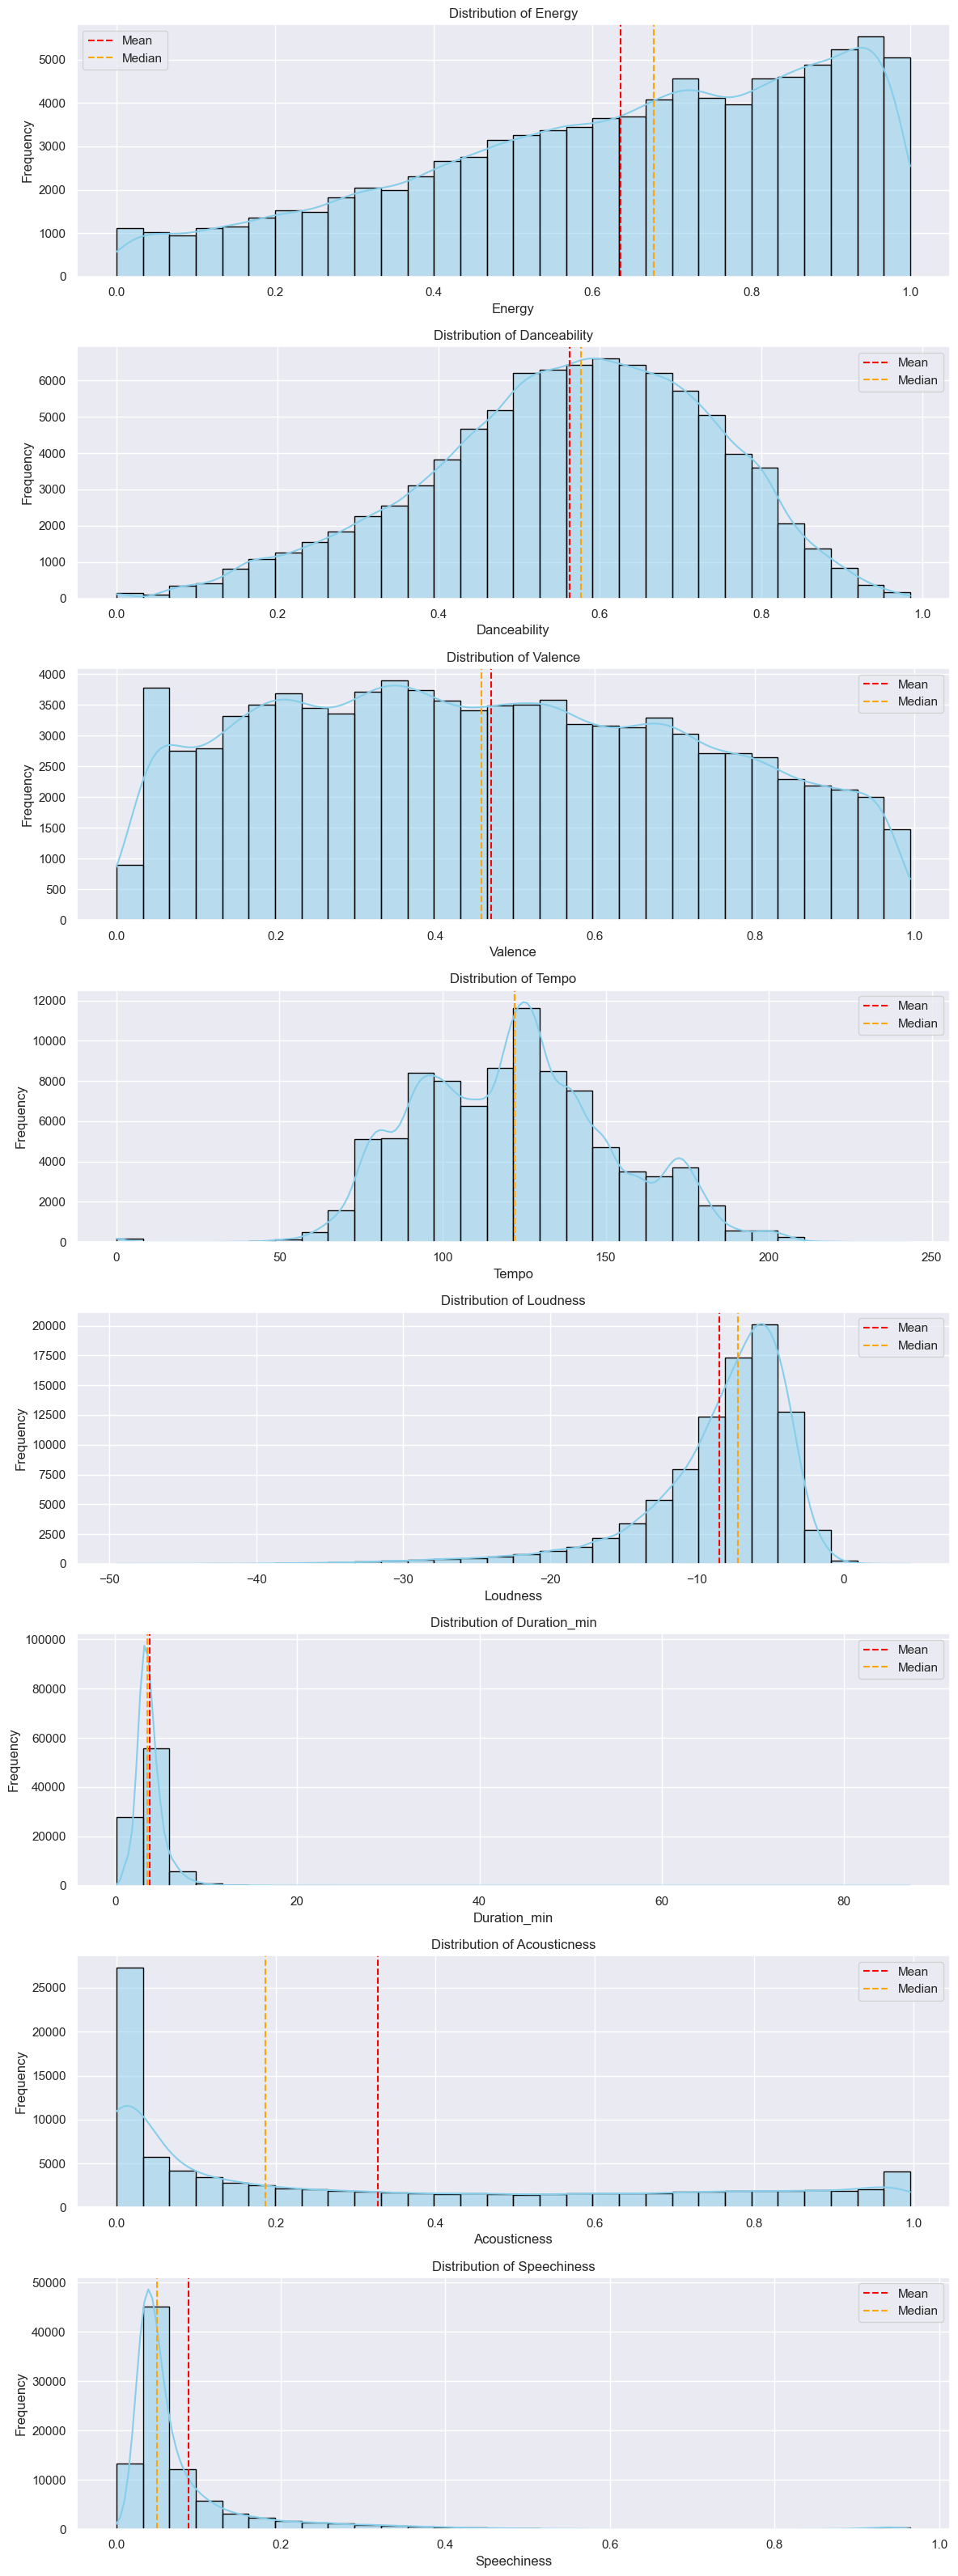

In [34]:
features = ['energy', 'danceability', 'valence', 'tempo', 'loudness', 'duration_min', 'acousticness', 'speechiness']
fig, ax= plt.subplots(len(features), 1, figsize=(12, 4 * len(features)))
for i, feature in enumerate(features):
    sns.histplot(df[feature], bins=30, kde=True, color='skyblue', edgecolor='black', ax=ax[i])
    ax[i].axvline(df[feature].mean(),   color='red',    linestyle='--', linewidth=1.5, label='Mean')
    ax[i].axvline(df[feature].median(), color='orange', linestyle='--', linewidth=1.5, label='Median')
    ax[i].legend()
    ax[i].set_title(f'Distribution of {feature.capitalize()}')
    ax[i].set_xlabel(feature.capitalize())
    ax[i].set_ylabel('Frequency')



plt.tight_layout()
plt.show()


### Target Distribution

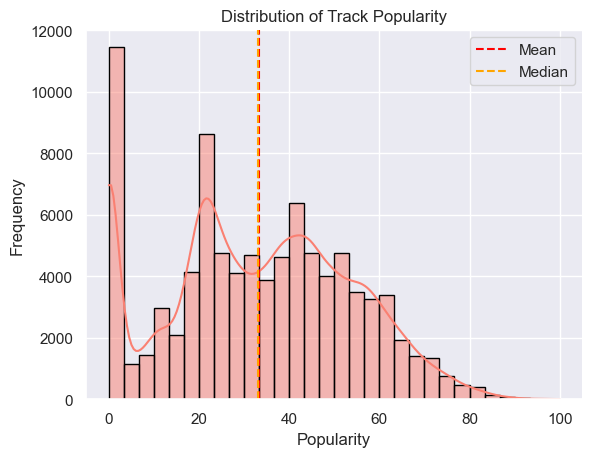

In [35]:
sns.histplot(df['popularity'], bins=30, kde=True, color='salmon', edgecolor='black')
sns.despine()
plt.title('Distribution of Track Popularity')
plt.xlabel('Popularity')
plt.ylabel('Frequency')
plt.axvline(df['popularity'].mean(),   color='red',    linestyle='--', linewidth=1.5, label='Mean')
plt.axvline(df['popularity'].median(), color='orange', linestyle='--', linewidth=1.5, label='Median')
plt.legend()
plt.show()

In [36]:
df.describe()

,popularity,duration_ms,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,duration_min,loudness_normalized
count,90460.0000,90460.0000,90460.0000,90460.0000,90460.0000,90460.0000,90460.0000,90460.0000,90460.0000,90460.0000,90460.0000,90460.0000,90460.0000,90460.0000,90460.0000,90460.0000
mean,33.2320,229132.1300,0.5625,0.6348,5.2841,-8.4904,0.6369,0.0874,0.3276,0.1729,0.2171,0.4698,122.0755,3.8979,3.8189,0.7591
std,20.6077,112745.8723,0.1766,0.2563,3.5598,5.2094,0.4809,0.1130,0.3380,0.3234,0.1950,0.2628,30.1150,0.4524,1.8791,0.0964
min,0.0000,8586.0000,0.0000,0.0000,0.0000,-49.5310,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.1431,0.0000
25%,19.0000,173045.5000,0.4500,0.4580,2.0000,-10.3120,0.0000,0.0360,0.0171,0.0000,0.0982,0.2500,99.2688,4.0000,2.8841,0.7254
50%,33.0000,213293.0000,0.5760,0.6770,5.0000,-7.1820,1.0000,0.0490,0.1870,0.0001,0.1320,0.4580,122.0170,4.0000,3.5549,0.7833
75%,49.0000,264240.0000,0.6920,0.8530,8.0000,-5.1070,1.0000,0.0858,0.6240,0.0954,0.2790,0.6830,140.0800,4.0000,4.4040,0.8217
max,100.0000,5237295.0000,0.9850,1.0000,11.0000,4.5320,1.0000,0.9650,0.9960,1.0000,1.0000,0.9950,243.3720,5.0000,87.2883,1.0000


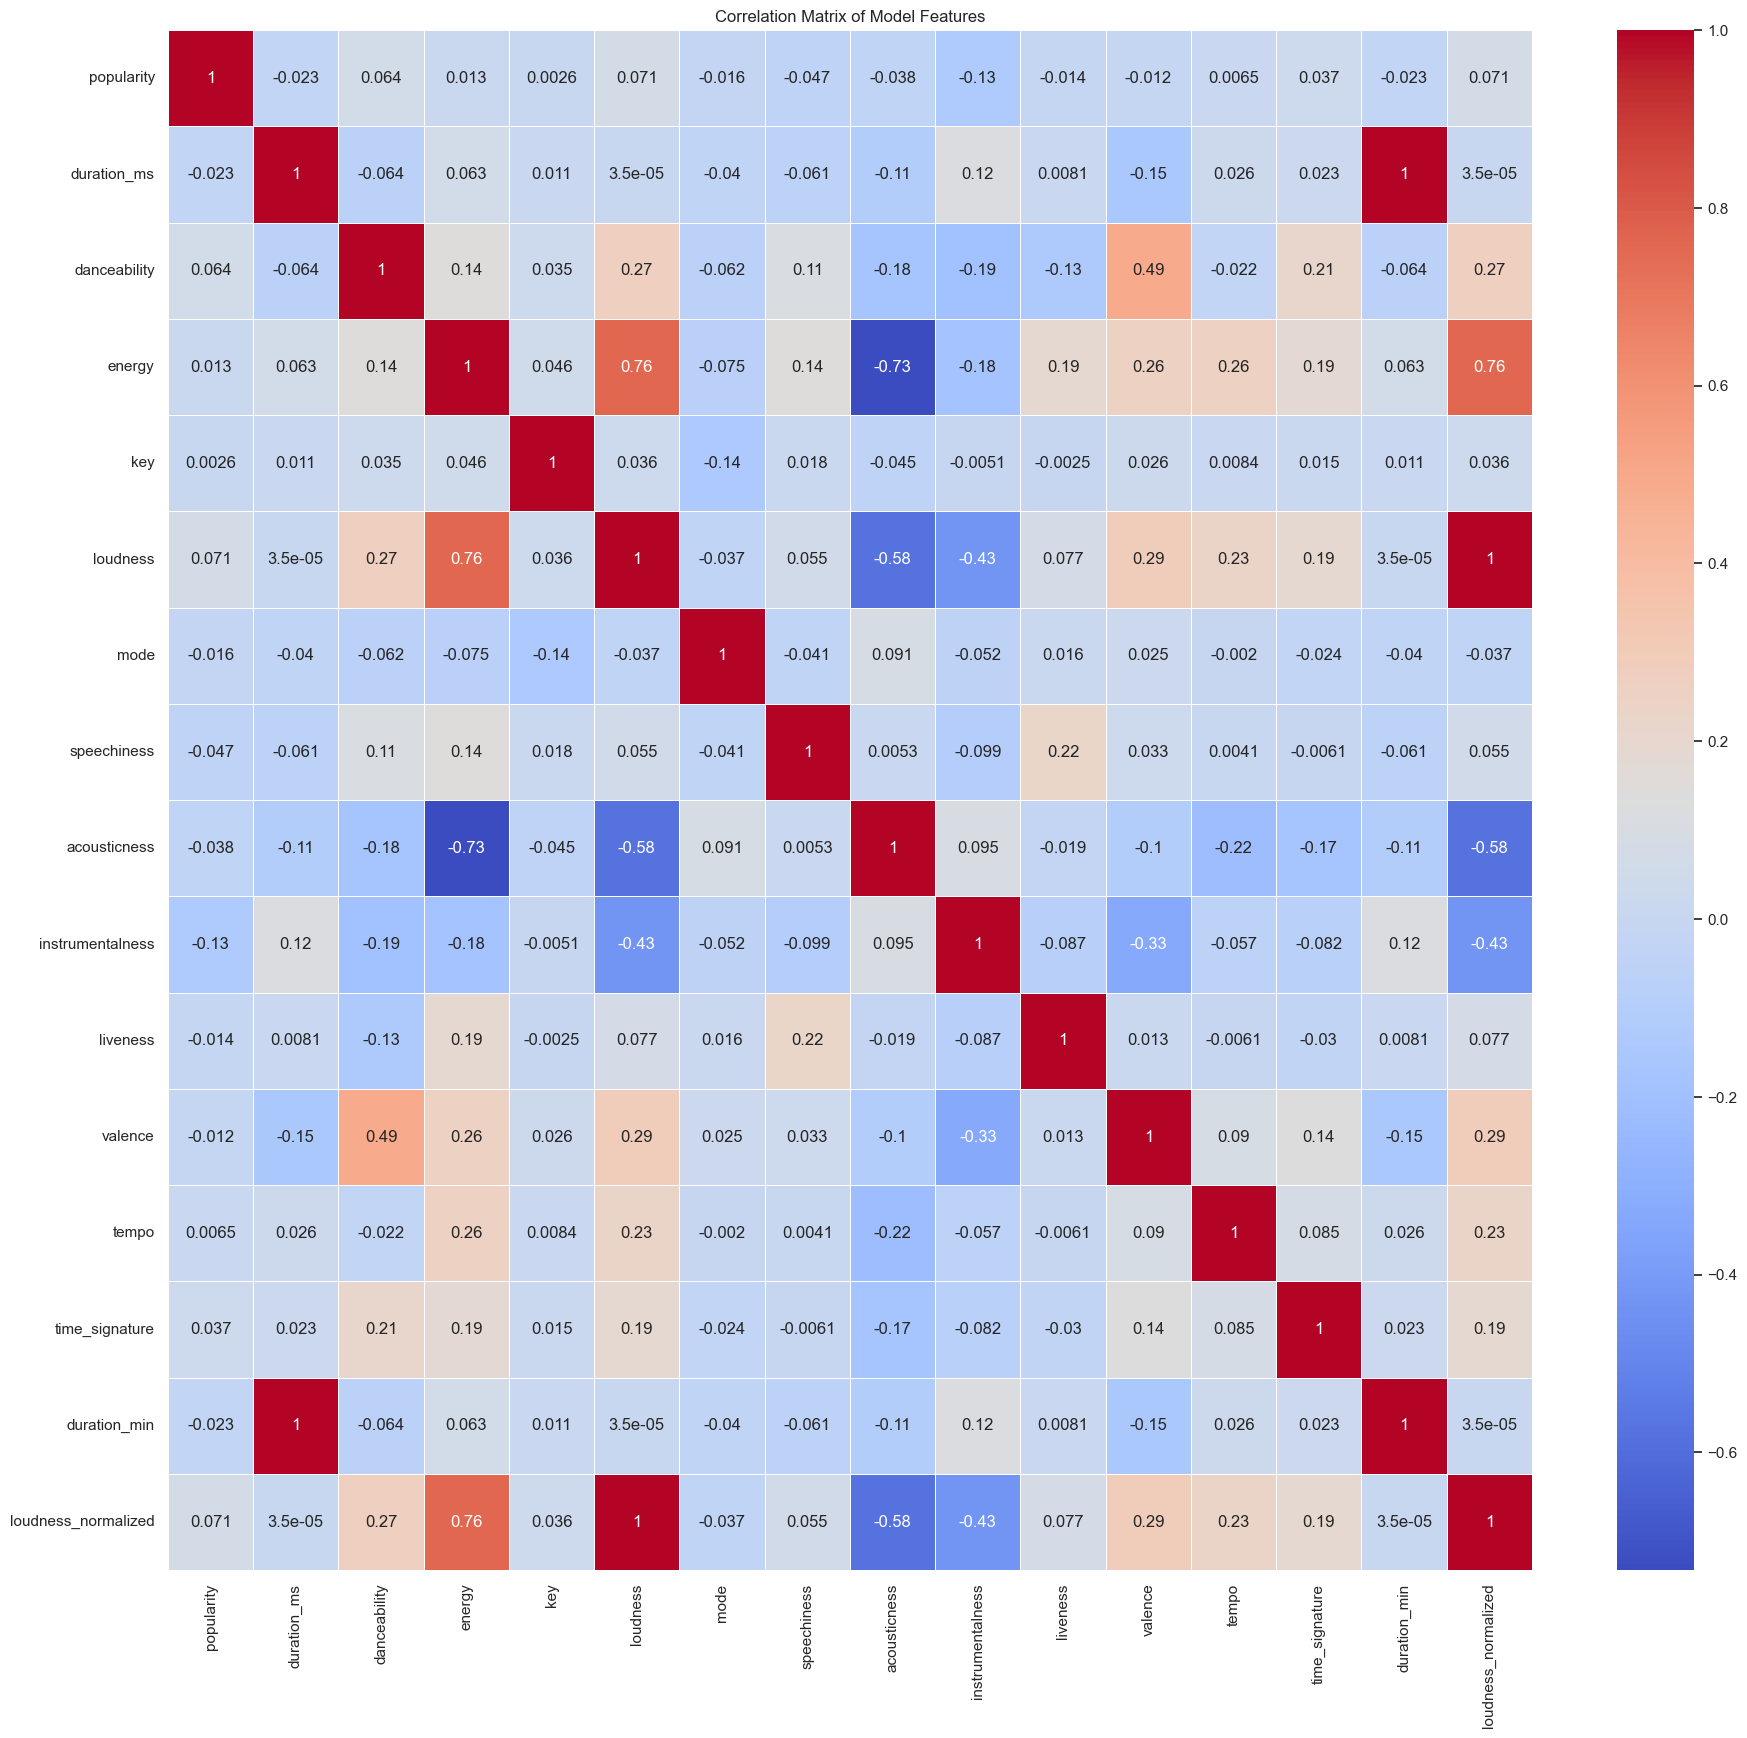

<Figure size 640x480 with 0 Axes>

In [37]:
cols = df.select_dtypes(include='number').columns.tolist()
plt.figure(figsize=(22, 20))
sns.heatmap(df[cols].corr(), annot=True, cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Matrix of Model Features')
plt.show()
plt.tight_layout()

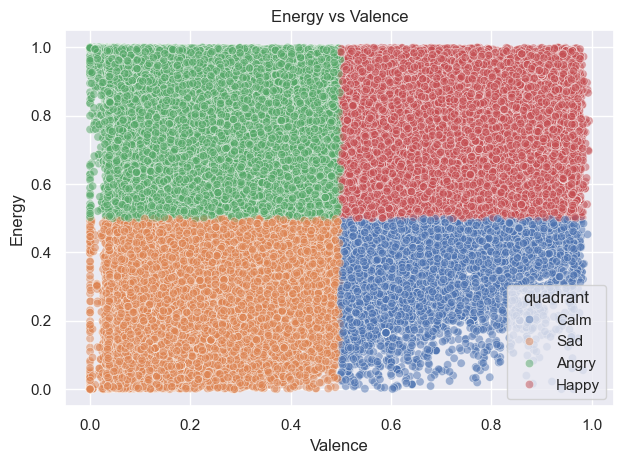

In [38]:
sns.scatterplot(x='valence', y='energy', data=df, hue = 'quadrant', alpha=0.5)
plt.title('Energy vs Valence')
plt.xlabel('Valence')
plt.ylabel('Energy')
plt.tight_layout()
plt.show()


### K-Means Clustering

In [39]:
df.head()

,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,...,liveness,valence,tempo,time_signature,track_genre,duration_min,loudness_normalized,energy_labeled,danceability_labeled,quadrant
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.6760,0.4610,1,...,0.3580,0.7150,87.9170,4,acoustic,3.8444,0.7914,Medium,High,Calm
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.4200,0.1660,1,...,0.1010,0.2670,77.4890,4,acoustic,2.4935,0.5974,Low,Low,Sad
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.4380,0.3590,0,...,0.1170,0.1200,76.3320,4,acoustic,3.5138,0.7361,Medium,Low,Sad
3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.2660,0.0596,0,...,0.1320,0.1430,181.7400,3,acoustic,3.3655,0.5737,Low,Low,Sad
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.6180,0.4430,2,...,0.0829,0.1670,119.9490,4,acoustic,3.3142,0.7371,Medium,Medium,Sad


### Focus on technical features of a song to classify while avoiding classifying a song based on the presence of vocals

In [40]:
df['tempo_scaled'] = MinMaxScaler().fit_transform(df[['tempo']])

# other features already in 0-1 scale

In [41]:
K_features = ['energy', 'danceability', 'valence', 'liveness', 'tempo_scaled', 'loudness_normalized']
x = df[K_features]
inertia_values = []
for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(x)

    inertia_values.append(kmeans.inertia_)




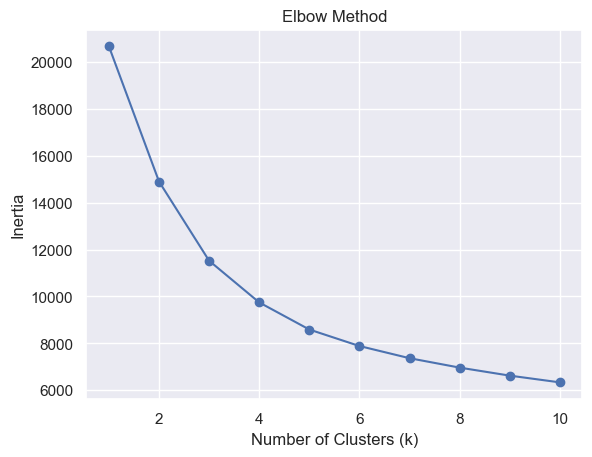

In [42]:
plt.plot(range(1,11), inertia_values, marker='o')

plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method')

plt.show()

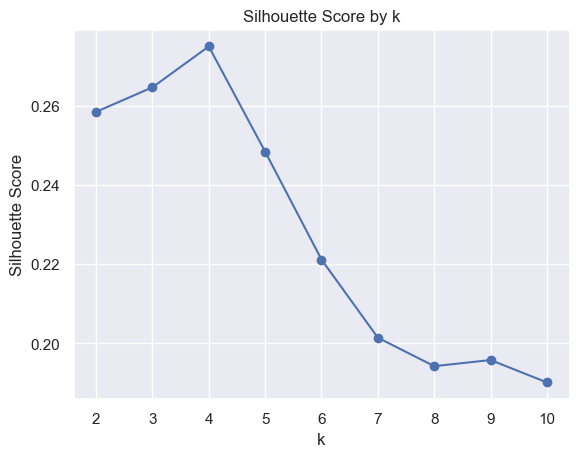

In [43]:
silhouette_scores = {}
for k in range(2, 11):
    km = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    labels = km.fit_predict(x)
    silhouette_scores[k] = silhouette_score(x, labels)

plt.plot(silhouette_scores.keys(), silhouette_scores.values(), marker='o')
plt.xlabel('k'); plt.ylabel('Silhouette Score')
plt.title('Silhouette Score by k')
plt.show()

In [44]:
# k=2 peaks on silhouette but produces trivially broad clusters.
# k=5 shows a secondary peak on silhouette and aligns with the 
# elbow method, while producing interpretable sonic archetypes.

kmeans = KMeans(n_clusters=5, init='k-means++', n_init=10, random_state=42)
kmeans.fit(x)
centers = pd.DataFrame(
    kmeans.cluster_centers_,
    columns=K_features
)
centers
centers.style.background_gradient(cmap='RdYlGn', axis=1)

,energy,danceability,valence,liveness,tempo_scaled,loudness_normalized
0,0.467365,0.638743,0.446617,0.149915,0.479222,0.739501
1,0.223883,0.369079,0.182786,0.156127,0.442498,0.611194
2,0.757948,0.667013,0.762538,0.176128,0.514196,0.797588
3,0.749019,0.517438,0.477589,0.751628,0.496176,0.772257
4,0.842496,0.483340,0.288388,0.192863,0.543399,0.810797


### Cluster 3 appears to uncover a structual pattern of live recordings, while other tracks appear to be seperated by genre or mood, these tracks are linked via their recording context.

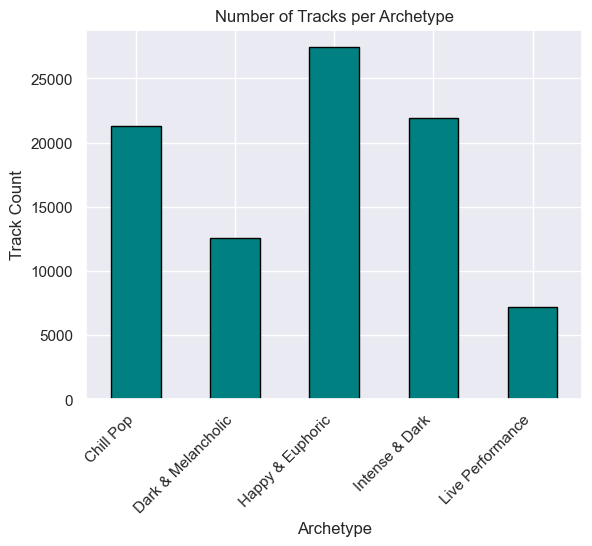

In [45]:
df['cluster'] = kmeans.labels_

archetype_map = {
    0: 'Chill Pop',
    1: 'Dark & Melancholic',
    2: 'Happy & Euphoric',
    3: 'Live Performance',
    4: 'Intense & Dark'
}
df['archetype'] = df['cluster'].map(archetype_map)

cluster_counts = df['archetype'].value_counts().sort_index()
cluster_counts.plot(kind='bar', color='teal', edgecolor='black')
plt.title('Number of Tracks per Archetype')
plt.xlabel('Archetype')
plt.ylabel('Track Count')
plt.xticks(rotation=45, ha='right')
plt.show()

In [46]:
df.head()

,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,...,time_signature,track_genre,duration_min,loudness_normalized,energy_labeled,danceability_labeled,quadrant,tempo_scaled,cluster,archetype
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.6760,0.4610,1,...,4,acoustic,3.8444,0.7914,Medium,High,Calm,0.3612,0,Chill Pop
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.4200,0.1660,1,...,4,acoustic,2.4935,0.5974,Low,Low,Sad,0.3184,1,Dark & Melancholic
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.4380,0.3590,0,...,4,acoustic,3.5138,0.7361,Medium,Low,Sad,0.3136,1,Dark & Melancholic
3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.2660,0.0596,0,...,3,acoustic,3.3655,0.5737,Low,Low,Sad,0.7468,1,Dark & Melancholic
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.6180,0.4430,2,...,4,acoustic,3.3142,0.7371,Medium,Medium,Sad,0.4929,0,Chill Pop


In [47]:
groups = [df[df['archetype'] == a]['popularity'].values for a in df['archetype'].unique()]
stats.f_oneway(*groups)

F_onewayResult(statistic=np.float64(98.95964989449911), pvalue=np.float64(3.38109321725981e-84))

ANOVA confirms that popularity differs significantly across sonic archetypes 
(F=98.96, p<0.001), suggesting that a track's audio DNA is meaningfully 
associated with its commercial performance on Spotify.

In [48]:
groups = [g['popularity'].values for _, g in df.groupby('archetype')]
f_stat, p_val = stats.f_oneway(*groups)

# eta squared = between-group variance / total variance
grand_mean = df['popularity'].mean()
ss_between = sum(len(g) * (g.mean() - grand_mean) ** 2 for g in groups)
ss_total = ((df['popularity'] - grand_mean) ** 2).sum()
eta_sq = ss_between / ss_total
print(f_stat, p_val, eta_sq)

98.95964989449912 3.38109321725981e-84 0.004357016464345936


### Random Forest on technical features

In [49]:
df_rf = df[features + ['popularity'] + ['archetype']].copy()
df_rf.head()

,energy,danceability,valence,tempo,loudness,duration_min,acousticness,speechiness,popularity,archetype
0,0.4610,0.6760,0.7150,87.9170,-6.7460,3.8444,0.0322,0.1430,73,Chill Pop
1,0.1660,0.4200,0.2670,77.4890,-17.2350,2.4935,0.9240,0.0763,55,Dark & Melancholic
2,0.3590,0.4380,0.1200,76.3320,-9.7340,3.5138,0.2100,0.0557,57,Dark & Melancholic
3,0.0596,0.2660,0.1430,181.7400,-18.5150,3.3655,0.9050,0.0363,71,Dark & Melancholic
4,0.4430,0.6180,0.1670,119.9490,-9.6810,3.3142,0.4690,0.0526,82,Chill Pop


In [50]:
X_train, X_test, y_train, y_test = train_test_split(df_rf[features], df_rf['popularity'], test_size=0.2, random_state=42)

In [51]:
rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"m

In [52]:
y_pred = rf.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f'MAE: {mae:.4f}')
print(f'RMSE: {rmse:.4f}')
print(f'R²: {r2:.4f}')

MAE: 13.6227
RMSE: 17.7676
R²: 0.2465


In [53]:
df_rf['predicted'] = rf.predict(df_rf[features])
df_rf['residual'] = df_rf['popularity'] - df_rf['predicted']
df_rf.groupby('archetype')['residual'].mean().round(2)

archetype
Chill Pop            0.3500
Dark & Melancholic   0.2900
Happy & Euphoric     0.2500
Intense & Dark       0.2200
Live Performance     0.2300
Name: residual, dtype: float64

In [54]:
df_rf.head()

,energy,danceability,valence,tempo,loudness,duration_min,acousticness,speechiness,popularity,archetype,predicted,residual
0,0.4610,0.6760,0.7150,87.9170,-6.7460,3.8444,0.0322,0.1430,73,Chill Pop,59.5550,13.4450
1,0.1660,0.4200,0.2670,77.4890,-17.2350,2.4935,0.9240,0.0763,55,Dark & Melancholic,44.9200,10.0800
2,0.3590,0.4380,0.1200,76.3320,-9.7340,3.5138,0.2100,0.0557,57,Dark & Melancholic,51.9800,5.0200
3,0.0596,0.2660,0.1430,181.7400,-18.5150,3.3655,0.9050,0.0363,71,Dark & Melancholic,60.6660,10.3340
4,0.4430,0.6180,0.1670,119.9490,-9.6810,3.3142,0.4690,0.0526,82,Chill Pop,64.7400,17.2600


### Shap for feature relevance

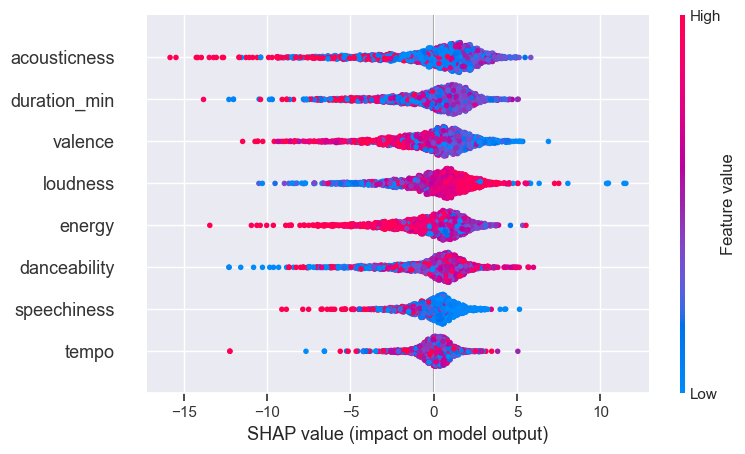

In [56]:


explainer = shap.TreeExplainer(rf)
X_sample = X_test.sample(2000, random_state=42)
shap_values = explainer.shap_values(X_sample)
shap.summary_plot(shap_values, X_sample)

As expected, audio features cannot directly predict popularity. Much more goes into a tracks popularity than just its technical components. That being said, Loudness is the most deterministic audio features of Spotify popularity — loud tracks score slightly higher on average. On the other hand, high energy seems to both help and hurt popularity on a case to case basis. Valence has no clear direction, tempo barely matters, and liveness actively hurts a tracks popularity. Audio features explain only ~25% of popularity variance — the rest is artist fame, marketing, and current trends. Had I combined more features such as artist and genre, my model would have performed better, but they would have dominated the models predictions. I wanted to explore if audion features had any predicitive power in predicting a track's popularity.